# jaxsedfit: fit one SED

This notebook fits the broadband SED of one *Chimera*: a real COSMOS galaxy with a scaled SDSS quasar spectrum added, so the true stellar mass is known. It covers

1. loading photometry and building a `FitConfig`;
2. running the fit;
3. comparing the recovered stellar mass to the truth;
4. plotting the SED, its components, and the posterior.

You need the DSPS SSP template file `tempdata.h5` in the repository root (see the installation instructions).

In [1]:
import numpy as np
import numpyro.distributions as dist
from astropy.table import Table

from jaxsedfit import (
    AGNConfig,
    FilterSet,
    FitConfig,
    GalaxyConfig,
    InferenceConfig,
    JAXSEDFit,
    LikelihoodConfig,
    Observation,
    PhotometryData,
    PriorConfig,
    load_filter_curves,
)

/Users/colinburke/miniforge3/envs/jaxcpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Photometry

Fluxes and errors are in mJy. The table metadata hold the redshift and the true stellar mass of the Chimera.

In [2]:
phot = Table.read("data/chimera_cosmos_891438.ecsv")
z = phot.meta["redshift"]
truth_log_mass = phot.meta["log_stellar_mass_truth"]
print(f"{phot.meta['object_id']}: z = {z:.3f}, true log M* = {truth_log_mass:.2f}")
phot

143317.88+173537.6_891438_0.03: z = 0.482, true log M* = 11.25


filter_name,flux_mjy,flux_err_mjy
str15,float64,float64
u_sdss,0.002428875467062975,7.875510654827021e-05
r_sdss,0.020759131063412796,0.0001537205761746448
i_sdss,0.042086479363879346,0.00018299706546085186
z_sdss,0.07049012348881123,0.00015239443981619063
J_2mass,0.11698025751531799,0.002088530278924525
H_2mass,0.17536422611417388,0.003318990959764527
Ks_2mass,0.20772608733692993,0.0029728648562782037
spitzer.irac.I1,0.18406519832562063,0.0007248001823870625
spitzer.irac.I2,0.15033218495048817,0.001138036898851082


## 2. Configure the fit

`FitConfig` groups the settings by section:

- `observation`: redshift (fixed here; `redshift_mode="fit"` with a `RedshiftPriorConfig` fits it as a photo-z, see the Fairall 9 photo-z tutorial);
- `photometry` and `filters`: the data and the filter transmission curves;
- `galaxy`: the stellar population, dust and SFH settings, including the DSPS SSP file;
- `agn`: the AGN model; `agn_type=1` is a type-1 quasar, `2` a Seyfert 2 and `3` a LINER;
- `likelihood`: error model options; `use_local_line_photometry` integrates emission lines through each filter exactly;
- `inference`: `method="optax+nuts"` (MAP warm start, then NUTS), `"optax"` (MAP only), or `"ns"` (nested sampling, with `ns_num_live_points`, `ns_max_samples`, `ns_dlogz`);
- `prior_config`: priors; here a broad Student-t prior on log stellar mass.

In [3]:
config = FitConfig(
    observation=Observation(object_id=phot.meta["object_id"], redshift=z, redshift_mode="fixed"),
    photometry=PhotometryData(
        filter_names=list(phot["filter_name"]),
        fluxes=list(phot["flux_mjy"]),
        errors=list(phot["flux_err_mjy"]),
    ),
    filters=FilterSet(curves=load_filter_curves(list(phot["filter_name"]))),
    galaxy=GalaxyConfig(dsps_ssp_fn="../tempdata.h5"),
    agn=AGNConfig(agn_type=1),
    likelihood=LikelihoodConfig(use_local_line_photometry=True),
    inference=InferenceConfig(
        method="optax+nuts",
        map_steps=400,
        learning_rate=5e-3,
        num_warmup=400,
        num_samples=200,
        max_tree_depth=8,
        target_accept_prob=0.8,
    ),
    prior_config=PriorConfig(stellar_mass=dist.StudentT(df=5.0, loc=10.0, scale=2.0)),
)

## 3. Fit and compare to the truth

In [4]:
fitter = JAXSEDFit(config)
result = fitter.fit(progress_bar=False)

lo, mid, hi = np.percentile(result.samples["log_stellar_mass"], [16, 50, 84])
print(f"log M*: {mid:.2f} (+{hi - mid:.2f}/-{mid - lo:.2f}), truth {truth_log_mass:.2f}, residual {mid - truth_log_mass:+.2f} dex")


                                 mean       std    median      5.0%     95.0%     n_eff     r_hat
       broad_lines_strength      4.10      4.79      2.03      0.33     12.41    148.62      1.02
                   cool_lam     20.68      6.34     21.54     11.28     29.66    104.50      1.00
                 cool_width      0.41      0.14      0.41      0.24      0.64    131.61      1.00
                 dust_alpha      1.72      0.58      1.68      0.96      2.71    121.12      1.02
                       fcov      0.49      0.27      0.47      0.13      0.94    165.40      1.00
                  feii_norm      7.58      7.56      4.44      0.65     19.23    157.88      1.01
                    hot_lam      3.11      1.34      3.27      1.00      5.08     49.22      1.00
                  hot_width      0.44      0.13      0.44      0.24      0.64    121.39      1.02
                log_agn_amp     80.27      2.63     80.72     76.18     84.01     74.58      1.03
  log_agn_systemati

/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/results.py:30: RuntimeWarning: All-NaN slice encountered
  out[key] = np.nanmedian(arr, axis=0)


## 4. SED and components

`plot_sed` draws the total model, the stellar host, the dust re-emission and the AGN components with the observed photometry. `predict()` returns the same model evaluated in each band; the first element of each array is the posterior median.

/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/plotting.py:1044: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


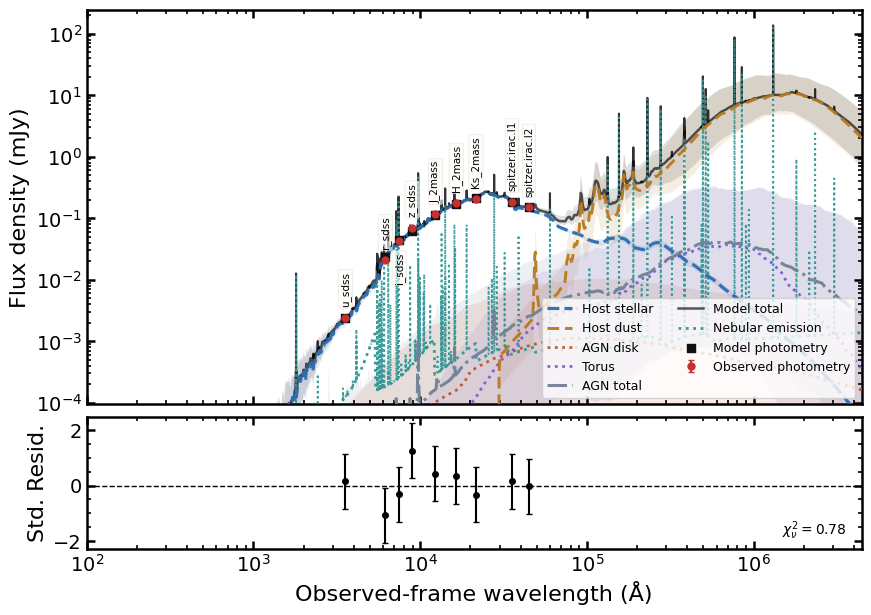

In [5]:
fitter.plot_sed(show=True);

In [6]:
pred = fitter.predict()
Table(
    {
        "filter": phot["filter_name"],
        "observed": phot["flux_mjy"],
        "model": pred["pred_fluxes"][0],
        "host": pred["host_fluxes"][0],
        "dust": pred["dust_fluxes"][0],
        "agn": pred["agn_fluxes"][0],
    }
)

filter,observed,model,host,dust,agn
str15,float64,float64,float64,float64,float64
u_sdss,0.002428875467062975,0.0024280660830309927,0.0024280660591227054,0.0,2.390828697552942e-11
r_sdss,0.020759131063412796,0.02180675006884317,0.021806747995365635,0.0,2.0734775337670232e-09
i_sdss,0.042086479363879346,0.041152797993843485,0.04115279018293101,0.0,7.810912472216578e-09
z_sdss,0.07049012348881123,0.05976991077684765,0.05976988563229607,0.0,2.514455158061668e-08
J_2mass,0.11698025751531799,0.10914759846498825,0.10914743024789664,0.0,1.682170915968491e-07
H_2mass,0.17536422611417388,0.1684917007150932,0.1684908765379717,0.0,8.241771215016874e-07
Ks_2mass,0.20772608733692993,0.21346710902608534,0.2134624146608625,0.0,4.694365222832814e-06
spitzer.irac.I1,0.18406519832562063,0.17451692698819596,0.17245265022528614,0.002031869446690815,3.240731621899539e-05
spitzer.irac.I2,0.15033218495048817,0.14453804668497217,0.1347671594603192,0.009714169726645908,5.6717498007029894e-05


## 5. Posterior

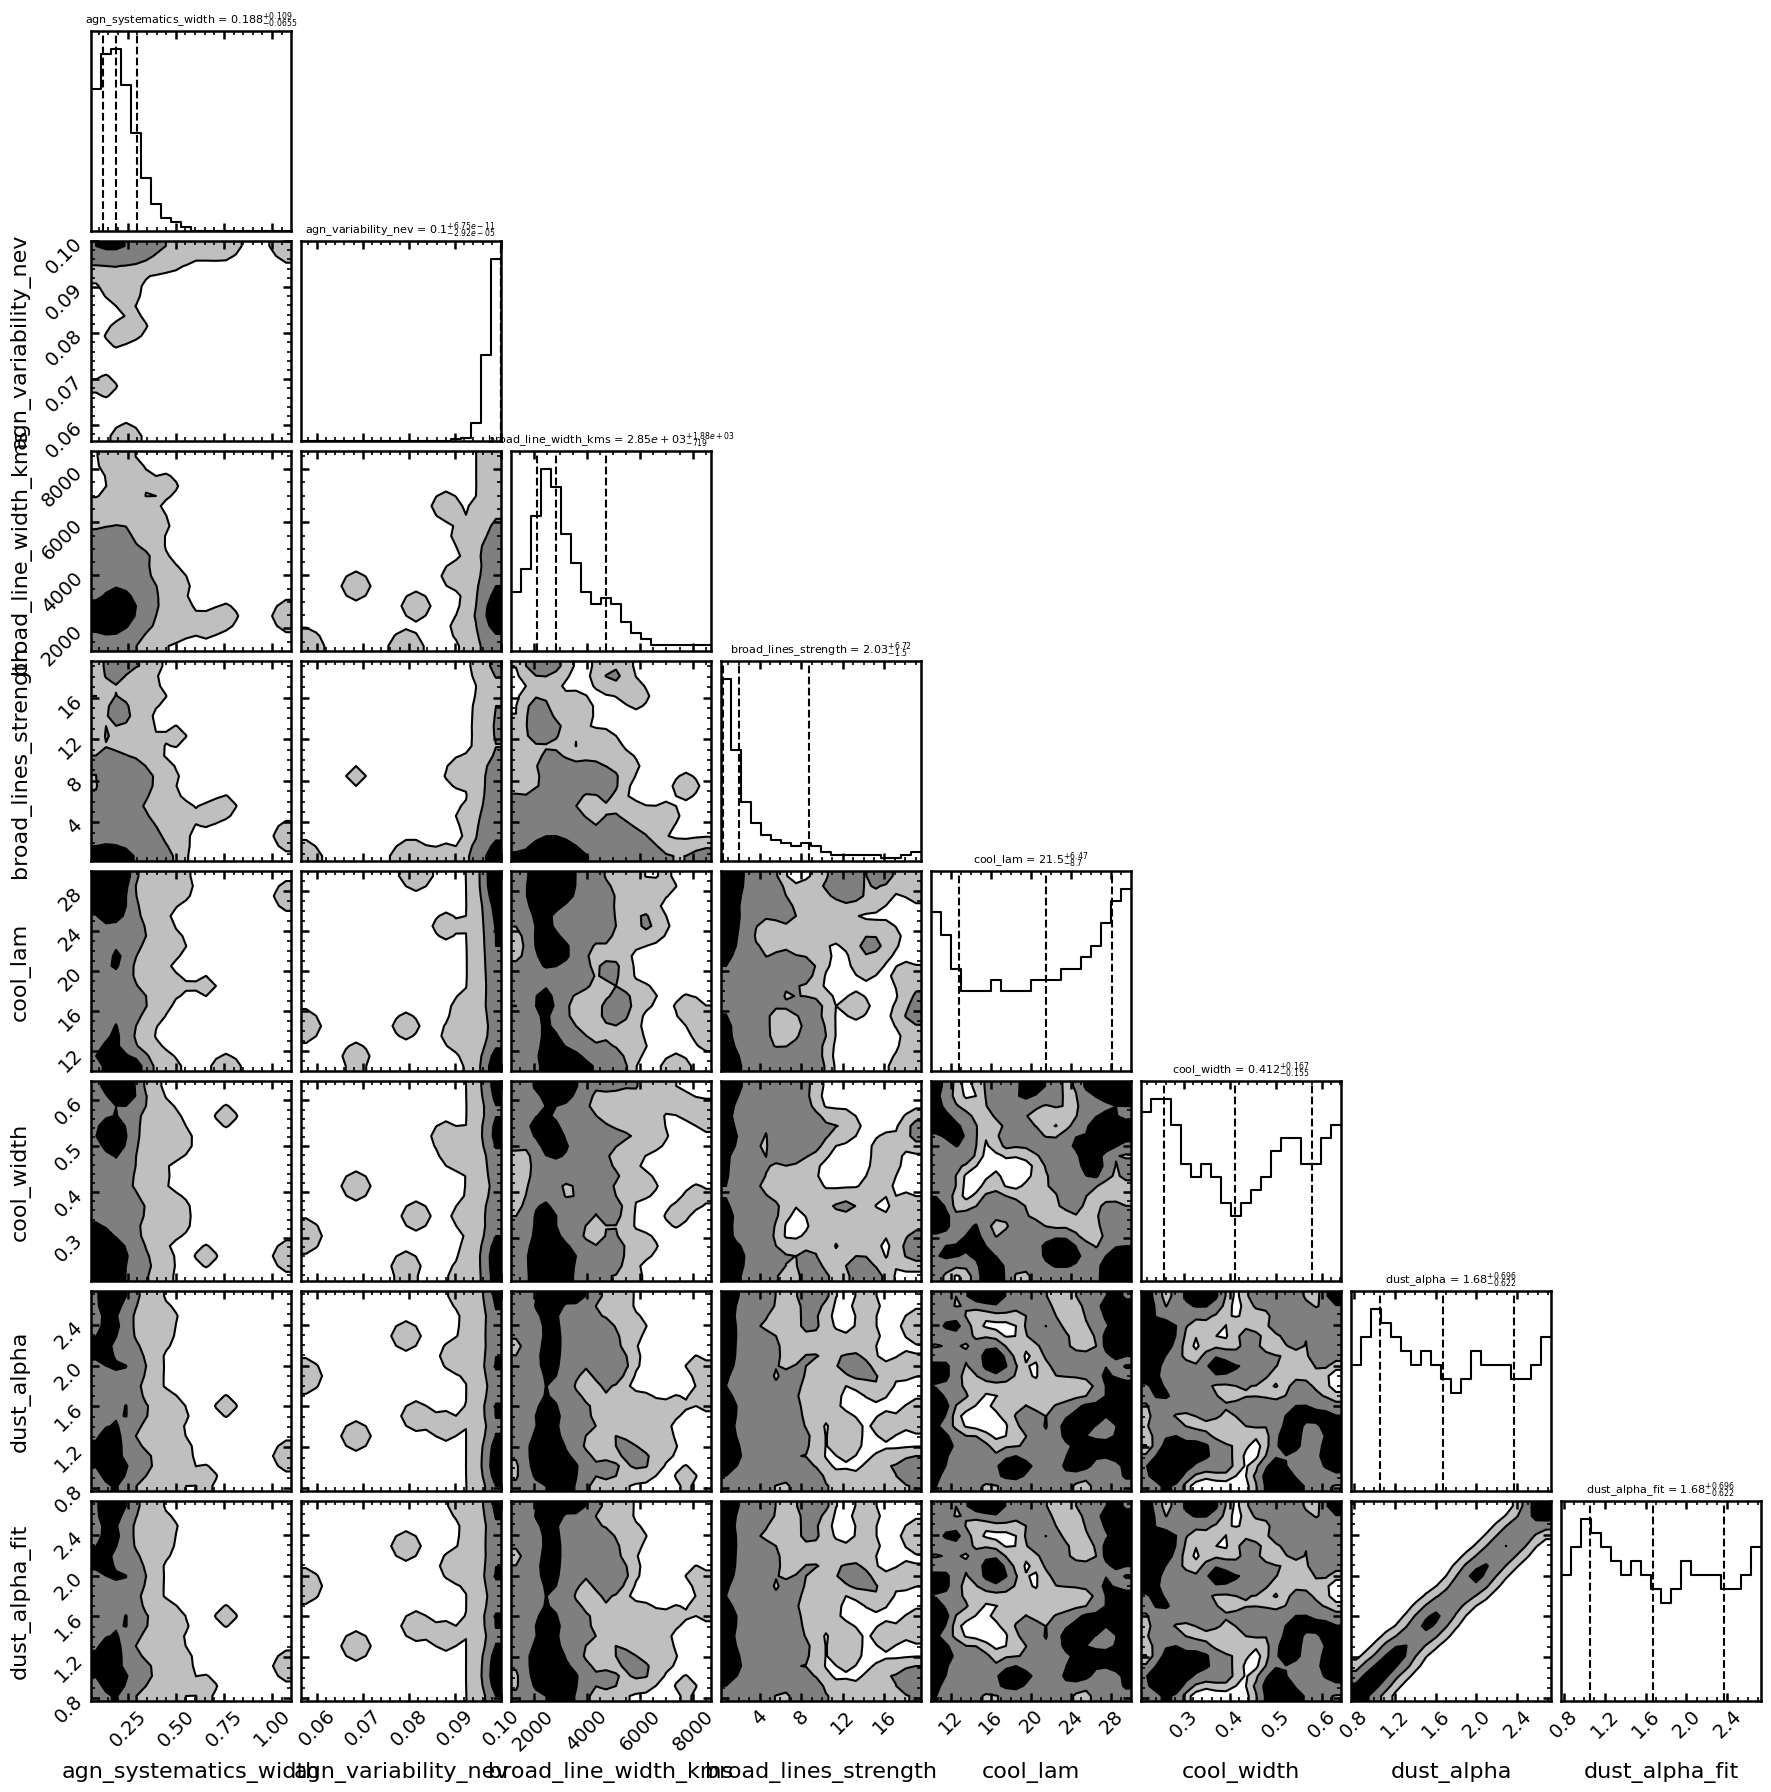

In [7]:
fitter.plot_corner(max_params=8, show=True);

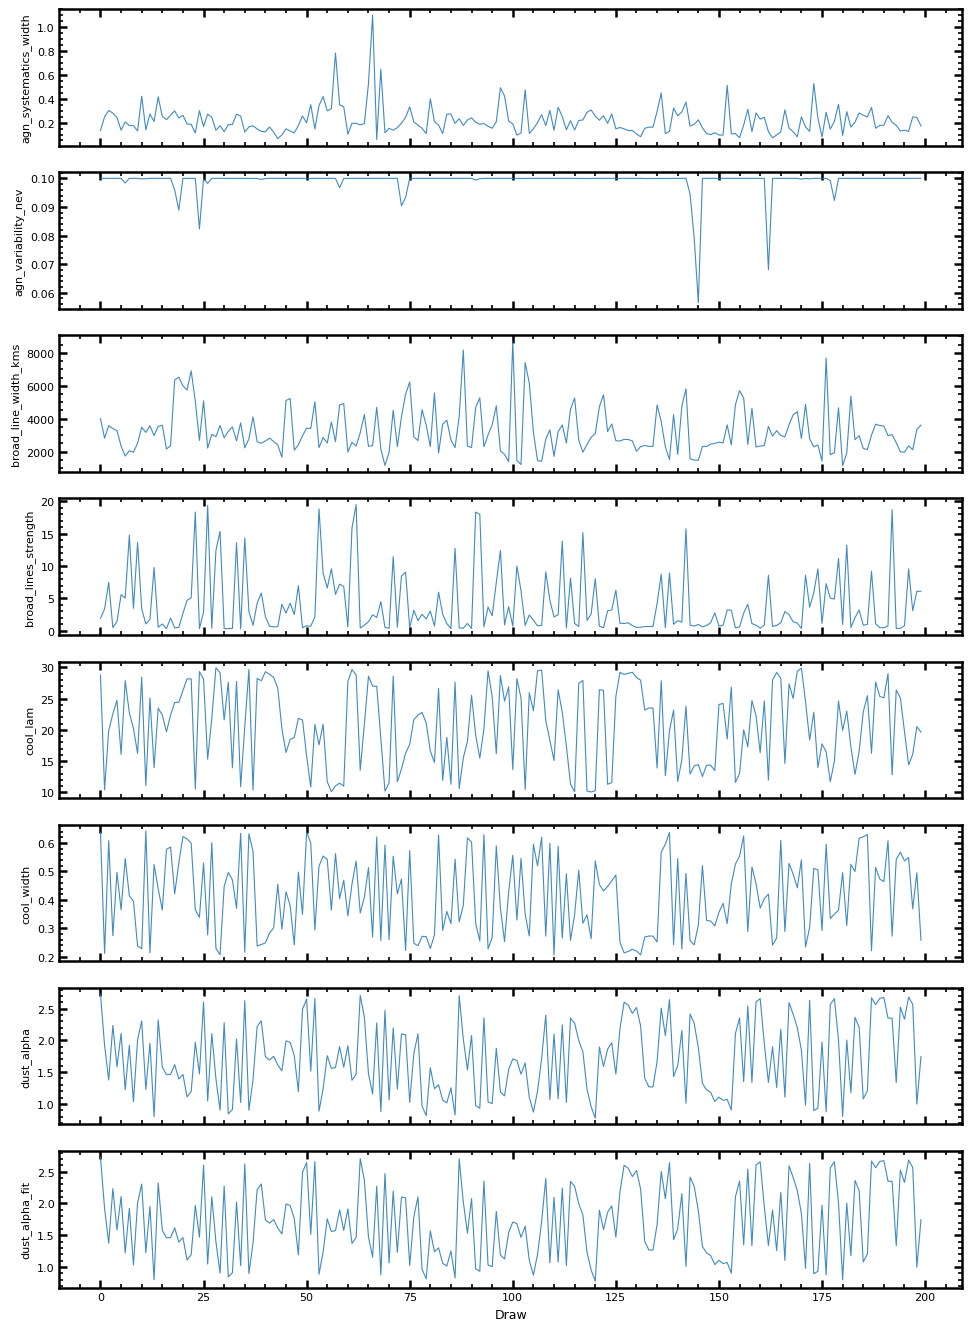

In [8]:
fitter.plot_trace(max_params=8, show=True);

## Next steps

- Increase `map_steps`, `num_warmup` and `num_samples` for science fits.
- Try `method="ns"` to compare with nested sampling.
- Save the posterior with `result.save(...)` and reload it with `jaxsedfit.load(...)`.
- Add the optical spectrum of this Chimera to the fit in the joint SED and spectrum tutorial.